# 01. Exploratory Data Analysis & Profiling (Tourism Analytics)
**Studi Kasus 08: Tourism Analytics**

Notebook ini bertujuan untuk melakukan profiling data awal, identifikasi missing values, dan eksplorasi statistik data transaksi *Hotel Booking Demand* dari Kaggle menggunakan **kagglehub**, **Pandas**, dan **SQL**.

In [15]:
# ==============================================================================
# CELL 1: IMPORT LIBRARY & LOADING DATASET
# ==============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Konfigurasi tampilan visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
pd.set_option('display.max_columns', None)

print("=" * 70)
print("1. PEMUATAN DATASET HOTEL BOOKING DEMAND")
print("=" * 70)

# Download dataset dari Kaggle
try:
    path = kagglehub.dataset_download(
        "jessemostipak/hotel-booking-demand"
    )

    csv_path = os.path.join(path, "hotel_bookings.csv")

except Exception as e:
    print("Download Kaggle gagal:", e)
    csv_path = "../data/raw/hotel_bookings.csv"

# Memastikan file tersedia
if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Dataset tidak ditemukan pada lokasi: {csv_path}"
    )

# Membaca dataset
df_raw = pd.read_csv(
    csv_path,
    na_values=['NA', 'NULL', 'null', 'undefined', 'Undefined']
)

# Menampilkan informasi dataset
print(f"\nJumlah Baris  : {df_raw.shape[0]:,}")
print(f"Jumlah Kolom  : {df_raw.shape[1]}")
print("\nPreview Dataset:")

display(df_raw.head())

1. PEMUATAN DATASET HOTEL BOOKING DEMAND
Using Colab cache for faster access to the 'hotel-booking-demand' dataset.

Jumlah Baris  : 119,390
Jumlah Kolom  : 32

Preview Dataset:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [16]:
# ==============================================================================
# CELL 2: PROFILING STRUKTUR DATA & MISSING VALUES
# ==============================================================================

print("=" * 70)
print("2. PROFILING DATA & MISSING VALUES")
print("=" * 70)

# Membuat ringkasan missing values
null_df = pd.DataFrame({
    'Tipe Data': df_raw.dtypes,
    'Jumlah Null': df_raw.isnull().sum(),
    'Persentase Null (%)': (
        df_raw.isnull().sum() / len(df_raw)
    ) * 100
})

# Mengambil kolom yang memiliki missing values
null_summary = (
    null_df[null_df['Jumlah Null'] > 0]
    .sort_values(by='Jumlah Null', ascending=False)
)

print("\nRingkasan Missing Values:")
display(null_summary)

# Pemeriksaan anomali bisnis
invalid_guests = df_raw[
    (
        df_raw['adults']
        + df_raw['children'].fillna(0)
        + df_raw['babies'].fillna(0)
    ) == 0
]

invalid_adr = df_raw[df_raw['adr'] < 0]

print("\nPemeriksaan Anomali Bisnis:")
print(f"Reservasi dengan 0 Tamu : {len(invalid_guests):,} baris")
print(f"Reservasi dengan ADR Negatif : {len(invalid_adr):,} baris")

2. PROFILING DATA & MISSING VALUES

Ringkasan Missing Values:


,Tipe Data,Jumlah Null,Persentase Null (%)
company,float64,112593,94.306893
agent,float64,16340,13.686238
meal,object,1169,0.979144
country,object,488,0.408744
distribution_channel,object,5,0.004188
children,float64,4,0.003350
market_segment,object,2,0.001675



Pemeriksaan Anomali Bisnis:
Reservasi dengan 0 Tamu : 180 baris
Reservasi dengan ADR Negatif : 1 baris


In [17]:

# ==============================================================================
# CELL 3: STATISTIK DESKRIPTIF VARIABEL NUMERIK
# ==============================================================================

print("=" * 70)
print("3. STATISTIK DESKRIPTIF VARIABEL NUMERIK")
print("=" * 70)

# Daftar variabel numerik yang diharapkan
num_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'booking_changes',
    'special_requests'
]

# Memeriksa kolom yang tersedia
available_cols = [
    col for col in num_cols
    if col in df_raw.columns
]

# Memeriksa kolom yang tidak ditemukan
missing_cols = [
    col for col in num_cols
    if col not in df_raw.columns
]

print("\nKolom numerik yang tersedia:")
print(available_cols)

if missing_cols:
    print("\nKolom yang tidak ditemukan:")
    print(missing_cols)

# Menghitung statistik deskriptif
numeric_summary = df_raw[available_cols].describe().T

display(numeric_summary)


3. STATISTIK DESKRIPTIF VARIABEL NUMERIK

Kolom numerik yang tersedia:
['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'adr', 'booking_changes']

Kolom yang tidak ditemukan:
['special_requests']


,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0
adr,119390.0,101.831122,50.535790,-6.38,69.29,94.575,126.0,5400.0
booking_changes,119390.0,0.221124,0.652306,0.00,0.00,0.000,0.0,21.0


In [18]:
# ==============================================================================
# CELL 4: PROFILING VARIABEL KATEGORIKAL UTAMA
# ==============================================================================

print("=" * 70)
print("4. PROFILING VARIABEL KATEGORIKAL UTAMA")
print("=" * 70)

# Daftar variabel kategorikal
cat_cols = [
    'hotel',
    'market_segment',
    'distribution_channel',
    'deposit_type',
    'customer_type'
]

# Menampilkan distribusi setiap variabel kategorikal
for col in cat_cols:

    print(f"\nDistribusi Variabel: {col.upper()}")
    print("-" * 50)

    distribution = (
        df_raw[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    display(distribution.to_frame(name='Persentase (%)'))

4. PROFILING VARIABEL KATEGORIKAL UTAMA

Distribusi Variabel: HOTEL
--------------------------------------------------


,Persentase (%)
hotel,
City Hotel,66.45
Resort Hotel,33.55



Distribusi Variabel: MARKET_SEGMENT
--------------------------------------------------


,Persentase (%)
market_segment,
Online TA,47.31
Offline TA/TO,20.29
Groups,16.59
Direct,10.56
Corporate,4.44
Complementary,0.62
Aviation,0.20



Distribusi Variabel: DISTRIBUTION_CHANNEL
--------------------------------------------------


,Persentase (%)
distribution_channel,
TA/TO,81.98
Direct,12.27
Corporate,5.59
GDS,0.16



Distribusi Variabel: DEPOSIT_TYPE
--------------------------------------------------


,Persentase (%)
deposit_type,
No Deposit,87.65
Non Refund,12.22
Refundable,0.14



Distribusi Variabel: CUSTOMER_TYPE
--------------------------------------------------


,Persentase (%)
customer_type,
Transient,75.06
Transient-Party,21.04
Contract,3.41
Group,0.48


5. ANALISIS BIVARIAT TERHADAP CANCELLATION RATE


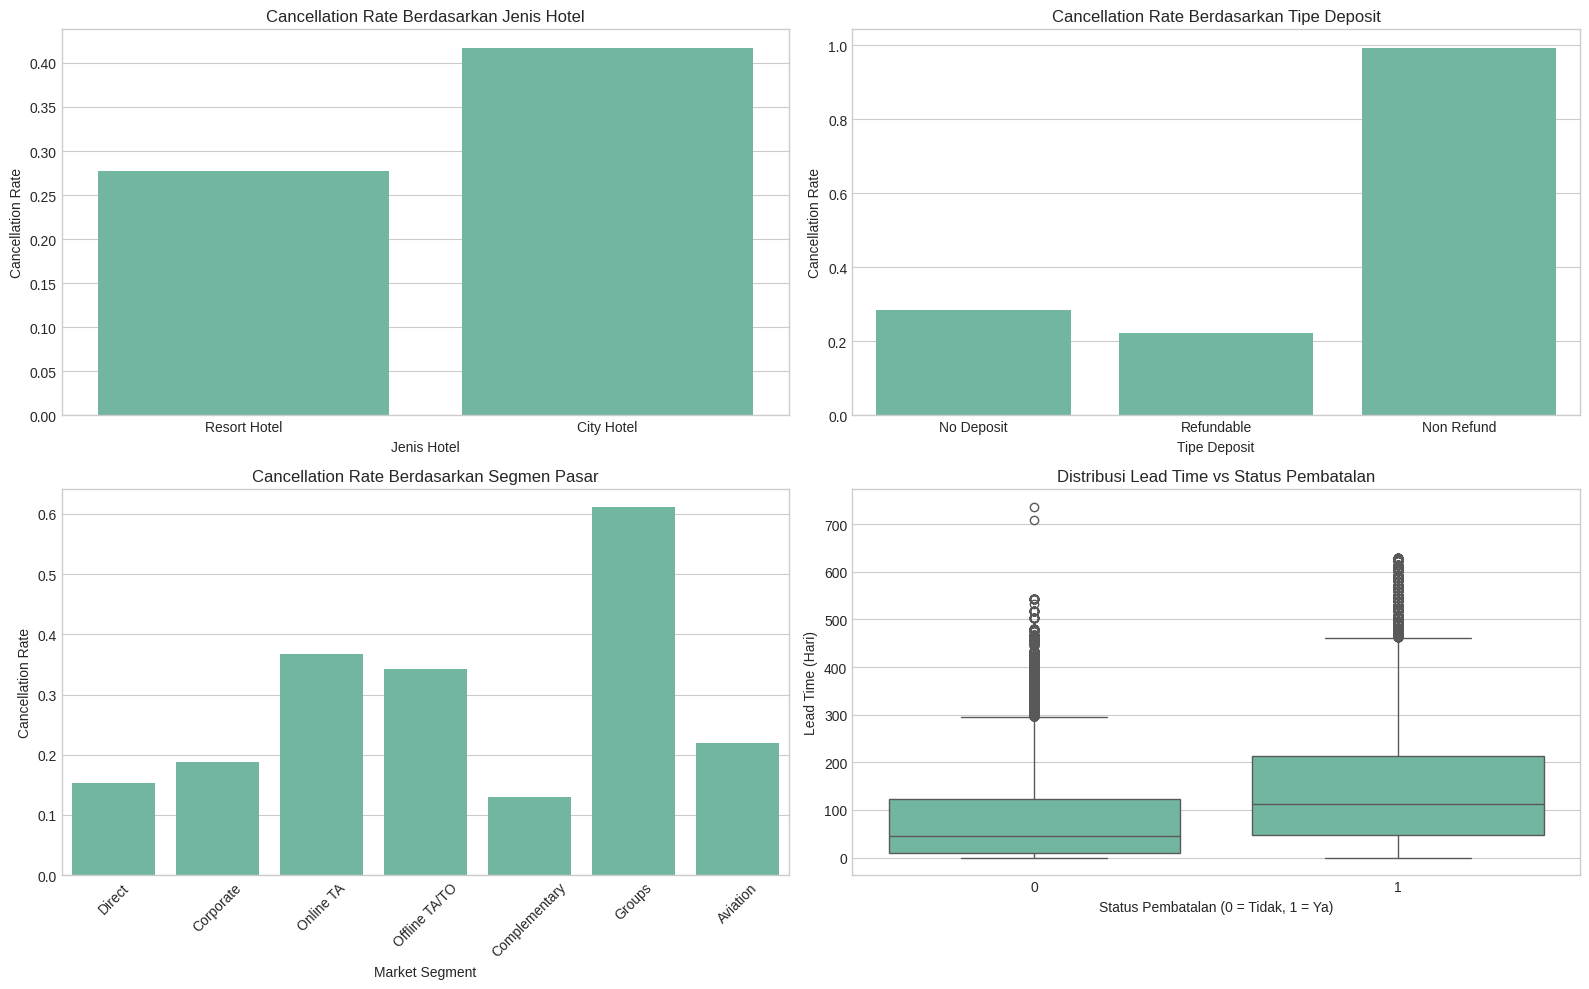

In [19]:
# ==============================================================================
# CELL 5: ANALISIS BIVARIAT TERHADAP CANCELLATION RATE
# ==============================================================================

print("=" * 70)
print("5. ANALISIS BIVARIAT TERHADAP CANCELLATION RATE")
print("=" * 70)

# Membuat layout visualisasi
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Cancellation Rate berdasarkan jenis hotel
sns.barplot(
    data=df_raw,
    x='hotel',
    y='is_canceled',
    ax=axes[0, 0],
    errorbar=None
)

axes[0, 0].set_title(
    'Cancellation Rate Berdasarkan Jenis Hotel'
)
axes[0, 0].set_xlabel('Jenis Hotel')
axes[0, 0].set_ylabel('Cancellation Rate')

# 2. Cancellation Rate berdasarkan deposit type
sns.barplot(
    data=df_raw,
    x='deposit_type',
    y='is_canceled',
    ax=axes[0, 1],
    errorbar=None
)

axes[0, 1].set_title(
    'Cancellation Rate Berdasarkan Tipe Deposit'
)
axes[0, 1].set_xlabel('Tipe Deposit')
axes[0, 1].set_ylabel('Cancellation Rate')

# 3. Cancellation Rate berdasarkan market segment
sns.barplot(
    data=df_raw,
    x='market_segment',
    y='is_canceled',
    ax=axes[1, 0],
    errorbar=None
)

axes[1, 0].set_title(
    'Cancellation Rate Berdasarkan Segmen Pasar'
)
axes[1, 0].set_xlabel('Market Segment')
axes[1, 0].set_ylabel('Cancellation Rate')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Distribusi lead time berdasarkan status pembatalan
sns.boxplot(
    data=df_raw,
    x='is_canceled',
    y='lead_time',
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    'Distribusi Lead Time vs Status Pembatalan'
)
axes[1, 1].set_xlabel('Status Pembatalan (0 = Tidak, 1 = Ya)')
axes[1, 1].set_ylabel('Lead Time (Hari)')

# Menampilkan visualisasi
plt.tight_layout()
plt.show()

6. ANALISIS KORELASI FITUR NUMERIK


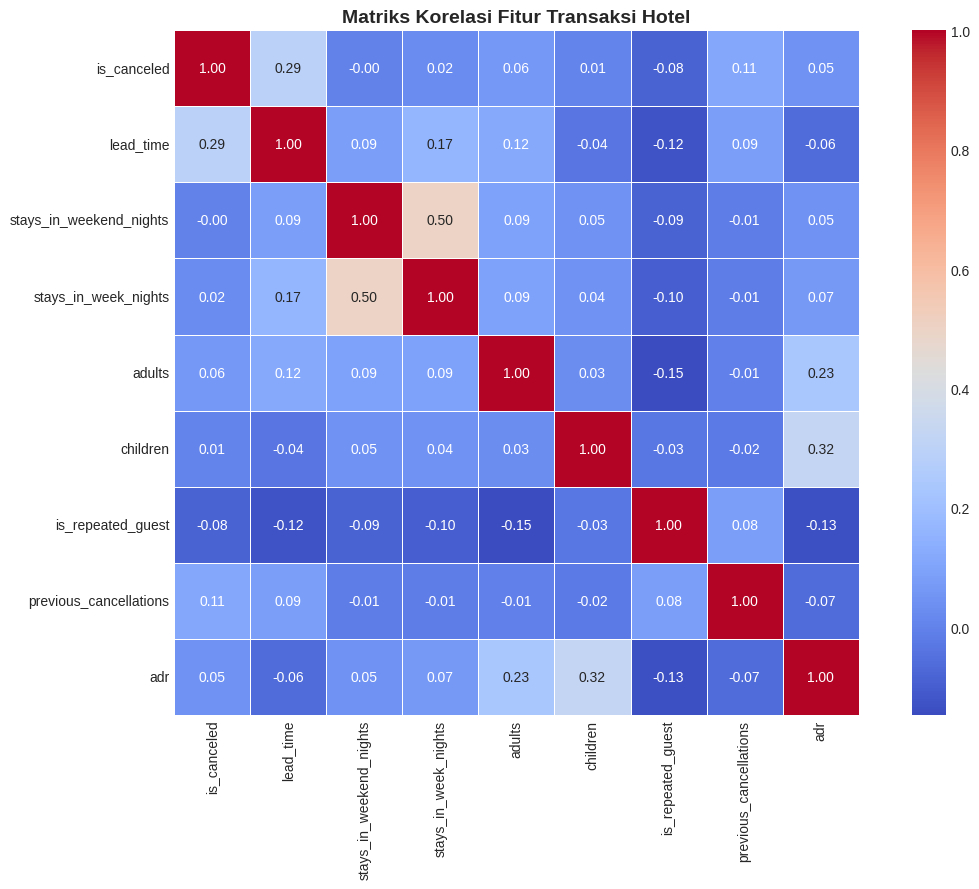

In [20]:
# ==============================================================================
# CELL 6: MATRIKS KORELASI FITUR NUMERIK
# ==============================================================================

print("=" * 70)
print("6. ANALISIS KORELASI FITUR NUMERIK")
print("=" * 70)

# Memilih variabel yang akan dianalisis
corr_cols = [
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'is_repeated_guest',
    'previous_cancellations',
    'adr'
]

# Menghitung korelasi
corr = df_raw[corr_cols].corr()

# Membuat visualisasi heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Matriks Korelasi Fitur Transaksi Hotel',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()